In [1]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np
import yfinance as yf
from datetime import datetime

In [2]:
prw = pd.read_excel("Dataset_EA-MPD.xlsx", sheet_name="Press Release Window")
pcw = pd.read_excel("Dataset_EA-MPD.xlsx", sheet_name="Press Conference Window")
mew = pd.read_excel("Dataset_EA-MPD.xlsx", sheet_name="Monetary Event Window")
mew["date"] = pd.to_datetime(mew["date"], dayfirst=True)

In [3]:
# Rolling std. over 3 years (8 ECB meetings per year)
mew["std_2Y_rolling"] = mew.OIS_2Y.rolling(24, min_periods=8).std()
mew["std_1M_rolling"] = mew.OIS_1M.rolling(24, min_periods=8).std()

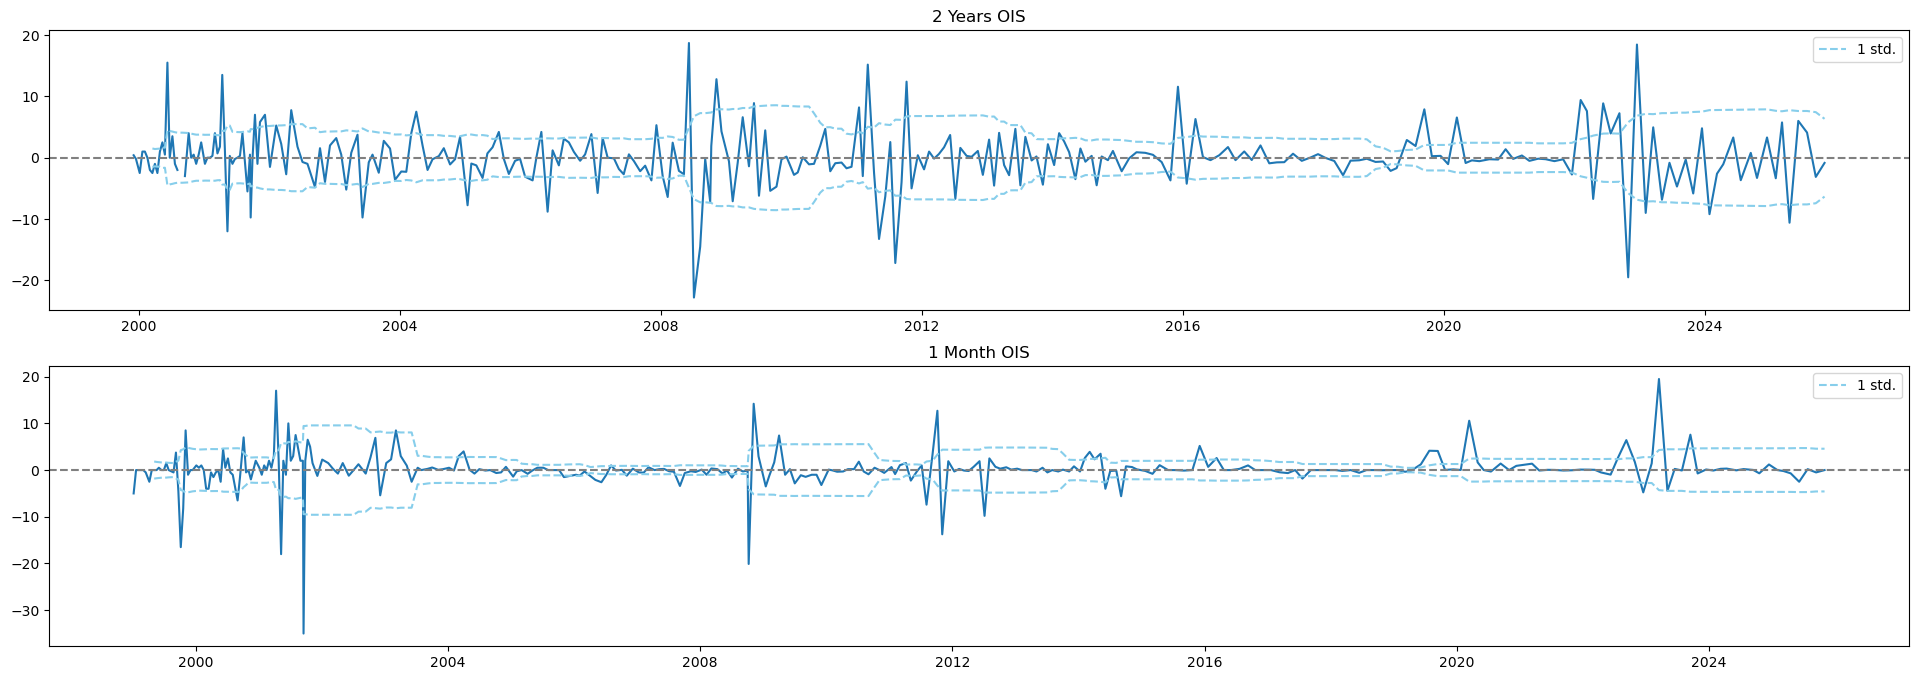

In [4]:
fig = plt.figure(figsize=(24, 8))

ax = fig.add_subplot(211)

ax.plot(mew["date"], mew["OIS_2Y"])
ax.plot(mew["date"], mew["std_2Y_rolling"], color='skyblue', linestyle='--', label="1 std.")
ax.plot(mew["date"], -mew["std_2Y_rolling"], color='skyblue', linestyle='--')
ax.set_title("2 Years OIS")
ax.axhline(y=0, color='gray', linestyle='--')
ax.legend()

ax = fig.add_subplot(212)

ax.plot(mew["date"], mew["OIS_1M"])
ax.plot(mew["date"], mew["std_1M_rolling"], color='skyblue', linestyle='--', label="1 std.")
ax.plot(mew["date"], -mew["std_1M_rolling"], color='skyblue', linestyle='--')
ax.set_title("1 Month OIS")
ax.axhline(y=0, color='gray', linestyle='--')
ax.legend()

In [5]:
mew["two_year_standardized"] = mew.OIS_2Y / mew.std_2Y_rolling
mew["one_month_standardized"] = mew.OIS_1M / mew.std_1M_rolling

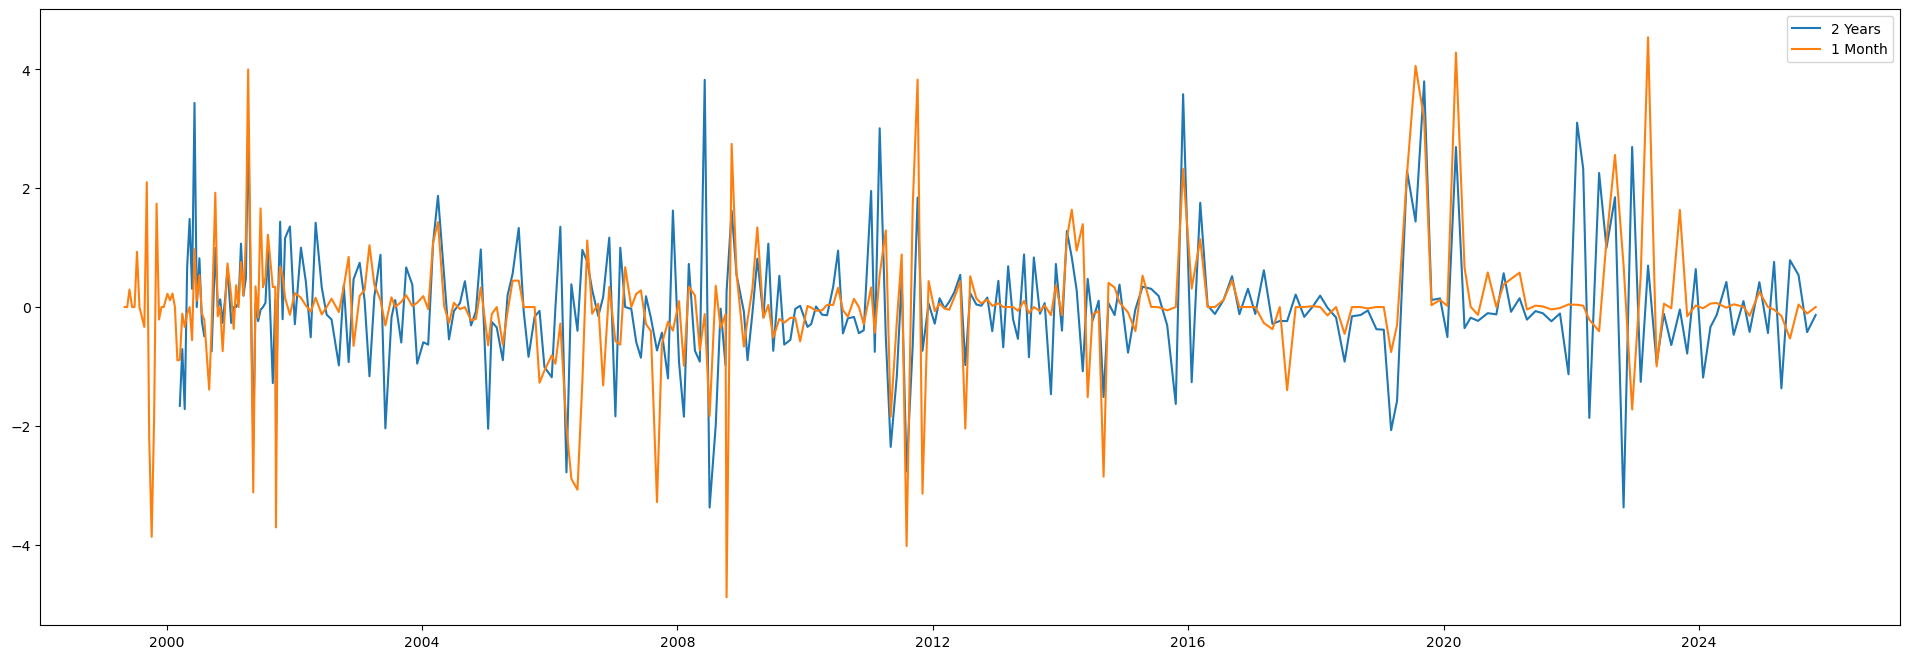

In [6]:
plt.figure(figsize=(24, 8))

plt.plot(mew["date"], mew["two_year_standardized"], label="2 Years")
plt.plot(mew["date"], mew["one_month_standardized"], label="1 Month")
plt.legend()

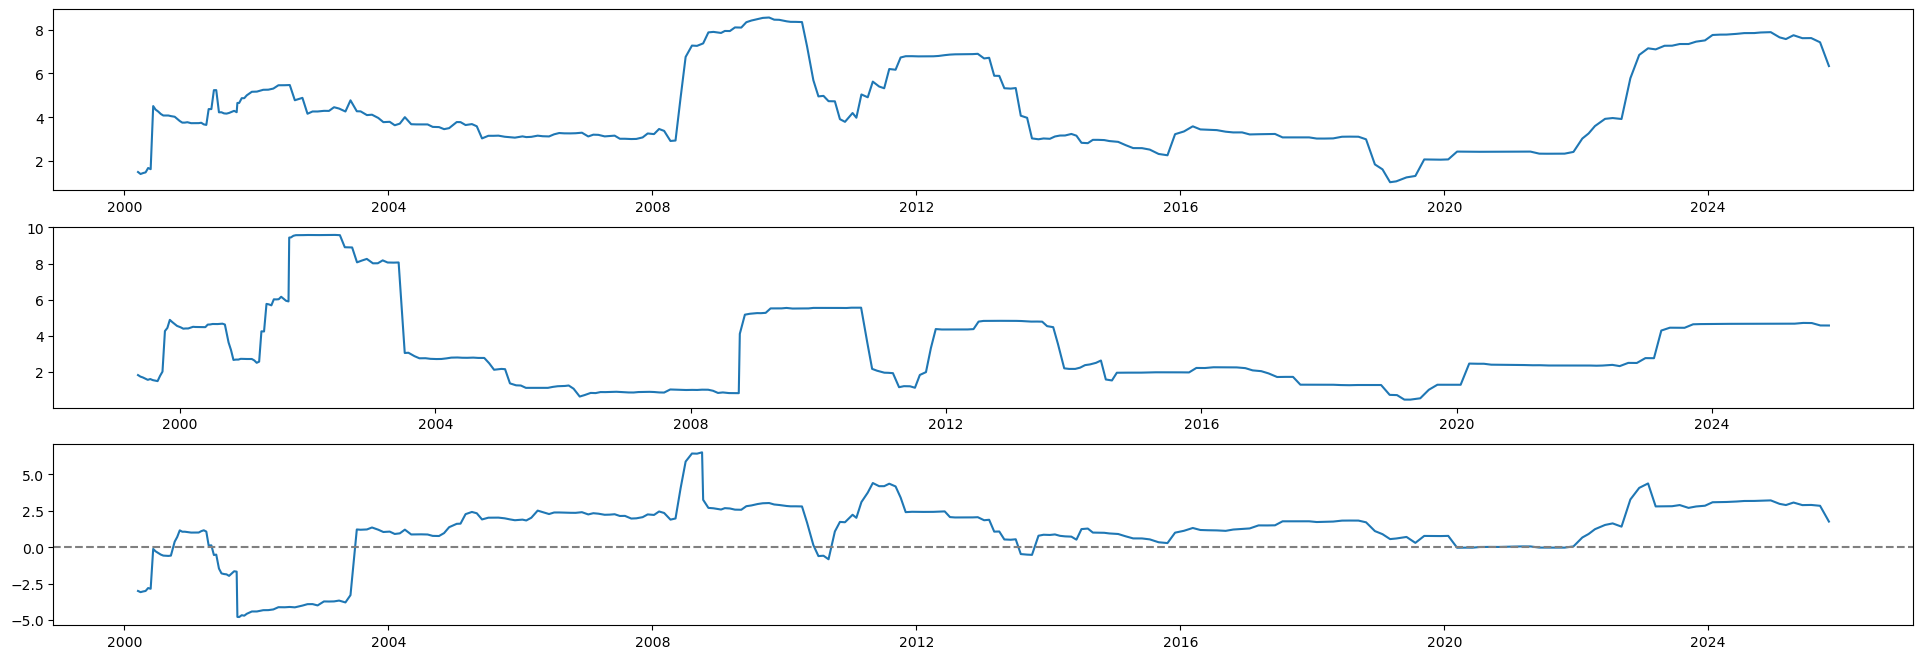

In [7]:
fig = plt.figure(figsize=(24, 8))
ax = fig.add_subplot(311)

ax.plot(mew["date"], mew["std_2Y_rolling"])

ax = fig.add_subplot(312)

ax.plot(mew["date"], mew["std_1M_rolling"])

ax = fig.add_subplot(313)

ax.plot(mew["date"], mew["std_2Y_rolling"] - mew["std_1M_rolling"])
ax.axhline(y=0, color='grey', linestyle='--')

In [8]:
mew["surprise_intensity"] = (mew["two_year_standardized"].abs() + mew["one_month_standardized"].abs()) / 2

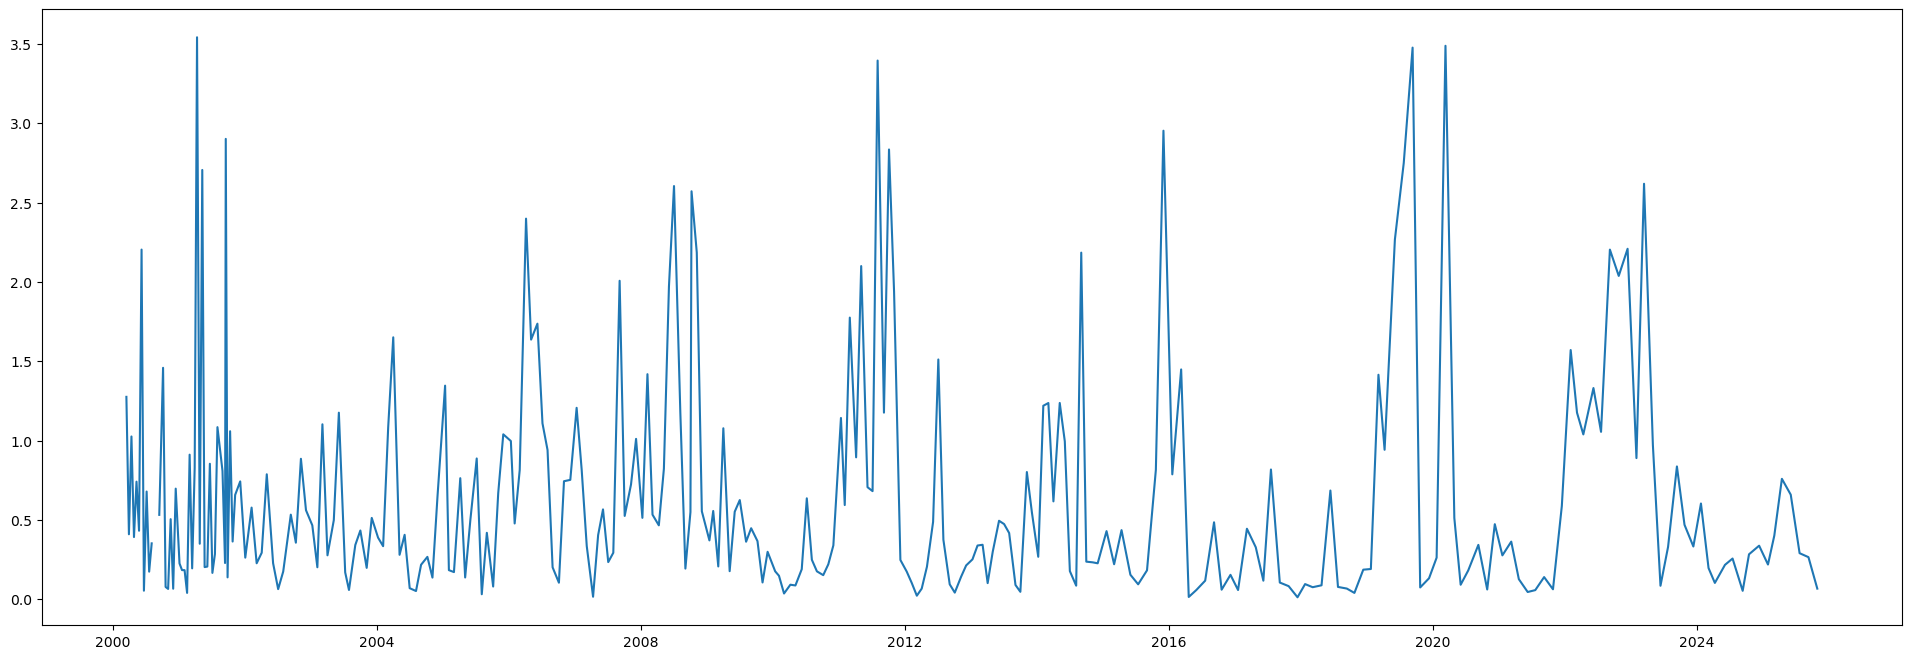

In [9]:
plt.figure(figsize=(24, 8))
plt.plot(mew["date"], mew["surprise_intensity"])

In [10]:
ois_cols_full_history = ['OIS_1M', 'OIS_3M', 'OIS_6M', 'OIS_1Y', 'OIS_2Y'] 
mew_long = mew[["date"] + ois_cols_full_history].dropna()
X_long = mew_long[ois_cols_full_history]
dates_long = mew_long["date"]

In [11]:
scaler_long = StandardScaler()
X_long_scaled = scaler_long.fit_transform(X_long)

In [12]:
pca_long = PCA()
pca_long.fit(X_long_scaled)

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [13]:
loadings = pd.DataFrame(pca_long.components_, columns=X_long.columns)
loadings

,OIS_1M,OIS_3M,OIS_6M,OIS_1Y,OIS_2Y
0,0.385070,0.463473,0.491585,0.465966,0.422060
1,0.659831,0.340244,-0.006835,-0.371570,-0.557446
2,0.634038,-0.525277,-0.385060,0.027963,0.415965
3,-0.117341,0.526501,-0.365317,-0.531590,0.541279
4,0.023890,-0.341040,0.690340,-0.601200,0.212390


In [14]:
scores_long = pca_long.transform(X_long_scaled)
scores_long[:, 0]

array([-5.35339619e-02, -1.16426525e-01, -8.21386950e-01,  4.77908725e-02,
        9.48188504e-01, -8.86196749e-02, -1.48554492e+00, -1.72178644e+00,
       -3.53286480e-01, -3.89866047e-01,  4.20120692e-01,  7.43979232e-01,
       -6.01567198e-01,  7.13856983e+00, -3.00218126e-01,  1.06506844e+00,
       -4.09887176e-01, -7.29516288e-01, -1.45559503e+00,  2.90286260e+00,
       -1.94287395e-02, -8.49479323e-02, -8.76879143e-01, -4.47625337e-02,
        8.99276841e-01,  6.77984467e-02,  3.05173081e-05,  1.51075440e-01,
        2.62885401e-01,  1.82870579e+00,  1.83103926e-01,  1.70800097e+00,
        7.12839165e+00,  3.96668045e-01, -9.03515620e+00,  2.22259050e-01,
       -6.02014623e-02,  1.44277429e+00,  7.12073949e-01,  6.33027319e-01,
        2.46109840e+00, -2.00351826e+00,  2.73400581e-01, -1.22483828e+01,
        4.63121481e-01,  3.34275820e+00,  7.99922138e-01,  1.45930222e+00,
        1.63052870e+00,  4.65268450e-01,  1.54822996e+00,  5.64331066e-01,
       -8.37405404e-01,  

In [15]:
pca_long.explained_variance_ratio_

array([0.80324122, 0.16413611, 0.02326343, 0.00590174, 0.00345751])

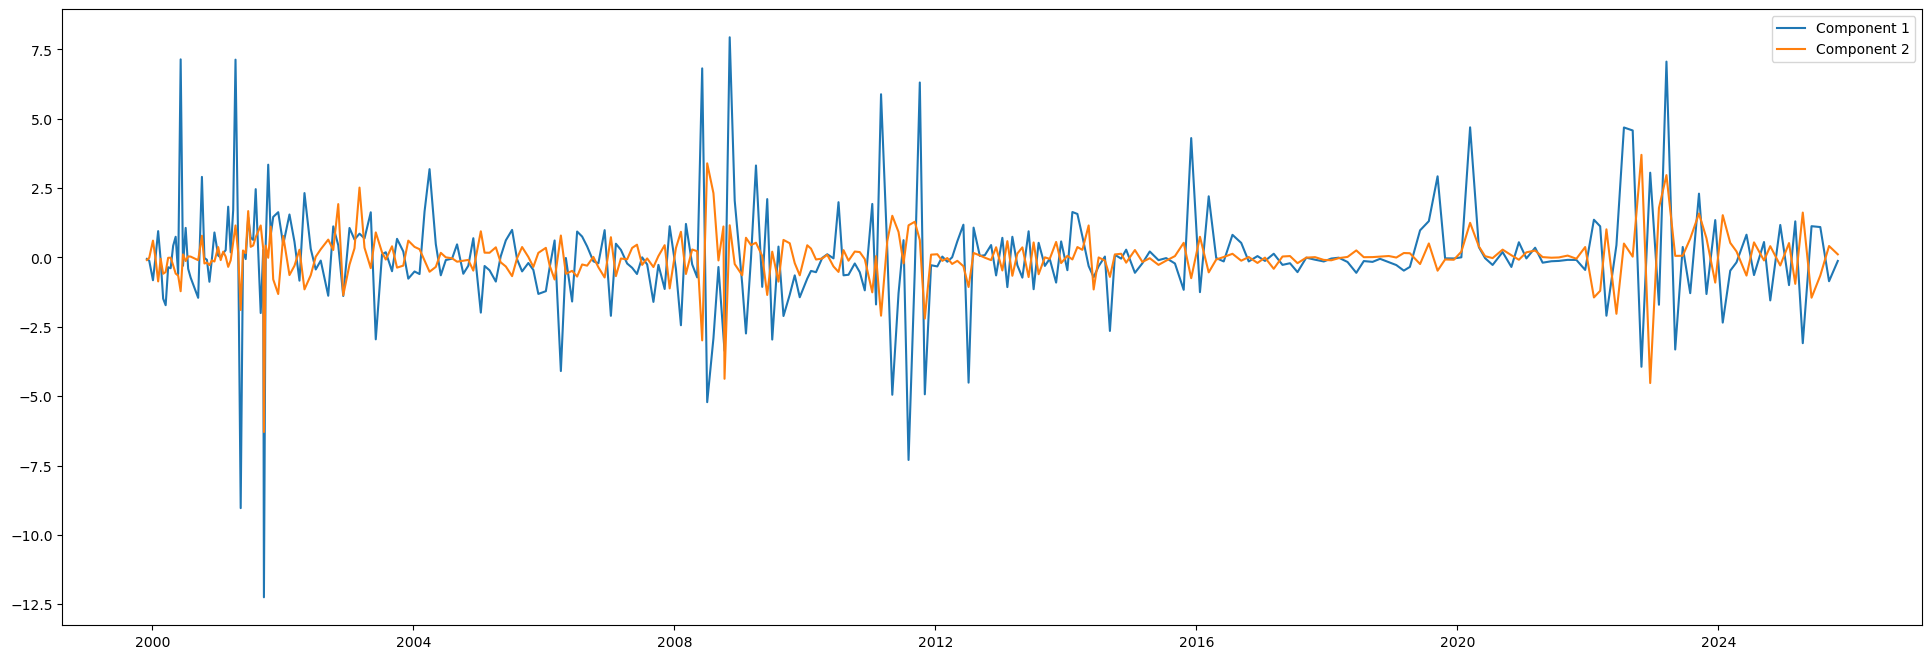

In [16]:
plt.figure(figsize=(24, 8))
plt.plot(dates_long, scores_long[:, 0], label="Component 1")
plt.plot(dates_long, scores_long[:, 1], label="Component 2")
plt.legend()

In [17]:
surprise_intensity_pca = 0.80324122 * np.absolute(scores_long[:, 0]) + 0.16413611 * np.absolute(scores_long[:, 1])

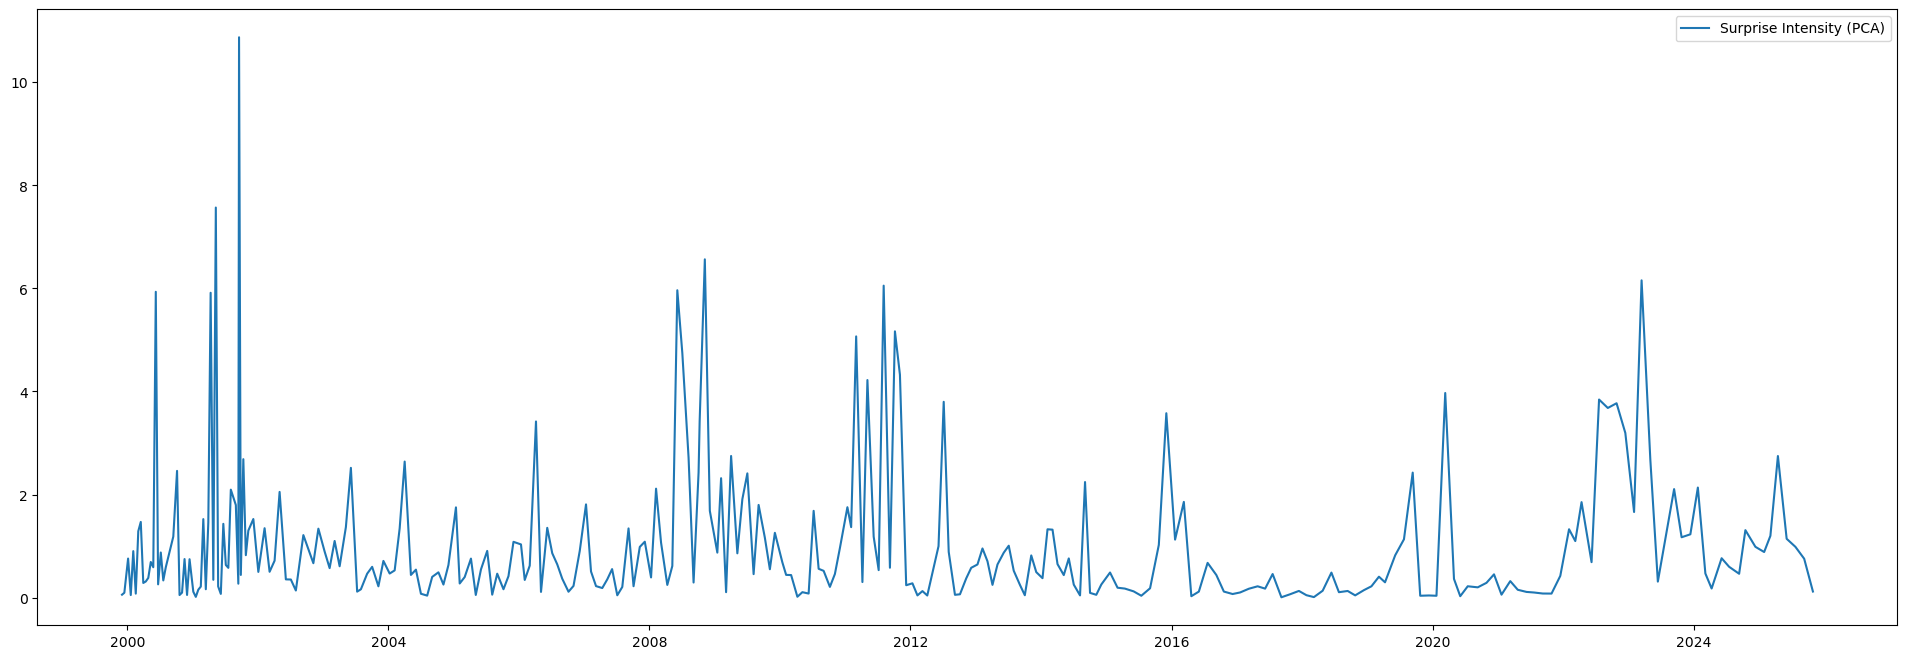

In [18]:
plt.figure(figsize=(24, 8))
plt.plot(dates_long, surprise_intensity_pca, label="Surprise Intensity (PCA)")
plt.legend()

In [19]:
price = yf.download(tickers="EXHD.DE", start=datetime(2008,1,1), end=datetime(2025,1,1), interval="1d", multi_level_index=False)

[*********************100%***********************]  1 of 1 completed


In [20]:
price

,Close,High,Low,Open,Volume
Date,,,,,
2008-01-02,92.185181,92.185181,92.185181,92.185181,0
2008-01-03,92.507492,92.507492,92.507492,92.507492,0
2008-01-04,92.920654,92.920654,92.920654,92.920654,0
2008-01-07,92.953735,92.953735,92.953735,92.953735,0
2008-01-08,92.755409,92.755409,92.755409,92.755409,0
...,...,...,...,...,...
2024-12-19,116.544182,116.836288,116.417607,116.553921,1404
2024-12-20,116.816811,116.894706,116.592869,116.797340,1359
2024-12-23,116.383522,116.709703,116.383522,116.480888,1407


In [21]:
returns = price.Close.pct_change()

In [22]:
returns

Date
2008-01-02         NaN
2008-01-03    0.003496
2008-01-04    0.004466
2008-01-07    0.000356
2008-01-08   -0.002134
                ...   
2024-12-19   -0.003497
2024-12-20    0.002339
2024-12-23   -0.003709
2024-12-27   -0.003388
2024-12-30    0.001511
Name: Close, Length: 4317, dtype: float64

In [23]:
import statsmodels.api as sm

surprise_df = pd.DataFrame({
    "date": dates_long.values,
    "surprise_intensity_pca": surprise_intensity_pca
})

returns_df = returns.rename("bund_return").reset_index()

# 3. Merge auf das Datum
merged_bund = surprise_df.merge(returns_df, left_on="date", right_on="Date", how="inner")

# 4. Regression
X_bund = sm.add_constant(merged_bund["surprise_intensity_pca"])
model_bund = sm.OLS(merged_bund["bund_return"].abs(), X_bund).fit()
model_bund.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            bund_return   R-squared:                       0.176
Model:                            OLS   Adj. R-squared:                  0.171
Method:                 Least Squares   F-statistic:                     34.72
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           2.12e-08
Time:                        13:55:14   Log-Likelihood:                 750.34
No. Observations:                 165   AIC:                            -1497.
Df Residuals:                     163   BIC:                            -1490.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0.0023      0.000      9.154      0.000       0.002       0.003
surprise_intensity_pca     0.0009      0.000      5.892      0.000       0.001       0.001
==============================================================================
Omnibus:                       62.098   Durbin-Watson:                   1.521
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              189.084
Skew:                           1.505   Prob(JB):                     8.73e-42
Kurtosis:                       7.294   Cond. No.                         2.54
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

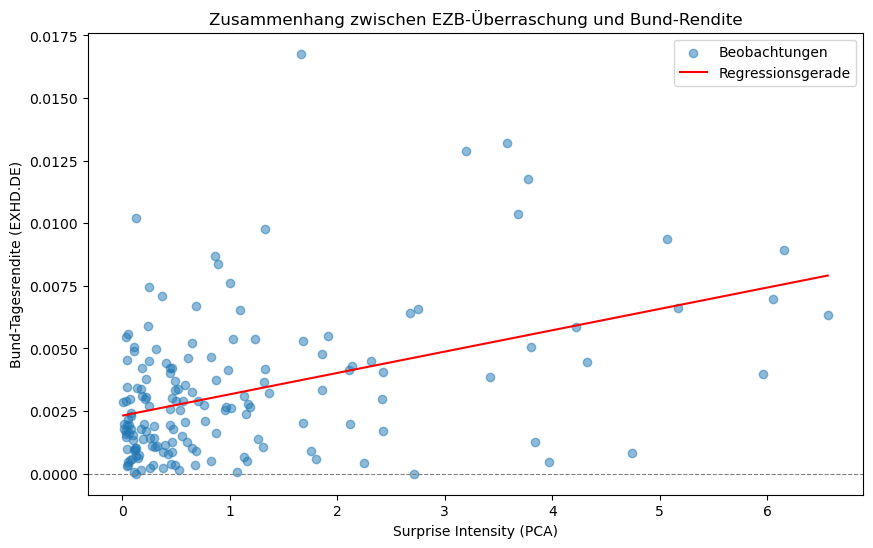

In [24]:
plt.figure(figsize=(10, 6))

# Datenpunkte
plt.scatter(merged_bund["surprise_intensity_pca"], merged_bund["bund_return"].abs(), alpha=0.5, label="Beobachtungen")

# Regressionsgerade
x_bund_range = np.linspace(merged_bund["surprise_intensity_pca"].min(), merged_bund["surprise_intensity_pca"].max(), 100)
y_bund_pred = model_bund.params["const"] + model_bund.params["surprise_intensity_pca"] * x_bund_range
plt.plot(x_bund_range, y_bund_pred, color="red", label="Regressionsgerade")

plt.xlabel("Surprise Intensity (PCA)")
plt.ylabel("Bund-Tagesrendite (EXHD.DE)")
plt.title("Zusammenhang zwischen EZB-Überraschung und Bund-Rendite")
plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)
plt.legend()
plt.show()

In [25]:
model_bund_robust = sm.OLS(merged_bund["bund_return"].abs(), X_bund).fit(cov_type="HC3")
model_bund_robust.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            bund_return   R-squared:                       0.176
Model:                            OLS   Adj. R-squared:                  0.171
Method:                 Least Squares   F-statistic:                     23.40
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           3.03e-06
Time:                        13:55:14   Log-Likelihood:                 750.34
No. Observations:                 165   AIC:                            -1497.
Df Residuals:                     163   BIC:                            -1490.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0.0023      0.000     11.102      0.000       0.002       0.003
surprise_intensity_pca     0.0009      0.000      4.837      0.000       0.001       0.001
==============================================================================
Omnibus:                       62.098   Durbin-Watson:                   1.521
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              189.084
Skew:                           1.505   Prob(JB):                     8.73e-42
Kurtosis:                       7.294   Cond. No.                         2.54
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [26]:
eurostoxx = yf.download(tickers="^STOXX50E", start=datetime(2008,1,1), end=datetime(2025,1,1), interval="1d", multi_level_index=False)
returns_eurostoxx = eurostoxx.Close.pct_change()
returns_eurostoxx_df = returns_eurostoxx.rename("EuroStoxx50_return").reset_index()
merged_eurostoxx = surprise_df.merge(returns_eurostoxx_df, left_on="date", right_on="Date", how="inner")

X_eurostoxx = sm.add_constant(merged_eurostoxx["surprise_intensity_pca"])
model_eurostoxx = sm.OLS(merged_eurostoxx["EuroStoxx50_return"].abs(), X_eurostoxx).fit()
model_eurostoxx.summary()

[*********************100%***********************]  1 of 1 completed


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     EuroStoxx50_return   R-squared:                       0.138
Model:                            OLS   Adj. R-squared:                  0.133
Method:                 Least Squares   F-statistic:                     26.04
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           9.28e-07
Time:                        13:55:15   Log-Likelihood:                 473.29
No. Observations:                 164   AIC:                            -942.6
Df Residuals:                     162   BIC:                            -936.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0.0078      0.001      5.811      0.000       0.005       0.010
surprise_intensity_pca     0.0039      0.001      5.103      0.000       0.002       0.005
==============================================================================
Omnibus:                      143.315   Durbin-Watson:                   1.609
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2526.354
Skew:                           3.072   Prob(JB):                         0.00
Kurtosis:                      21.220   Cond. No.                         2.54
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

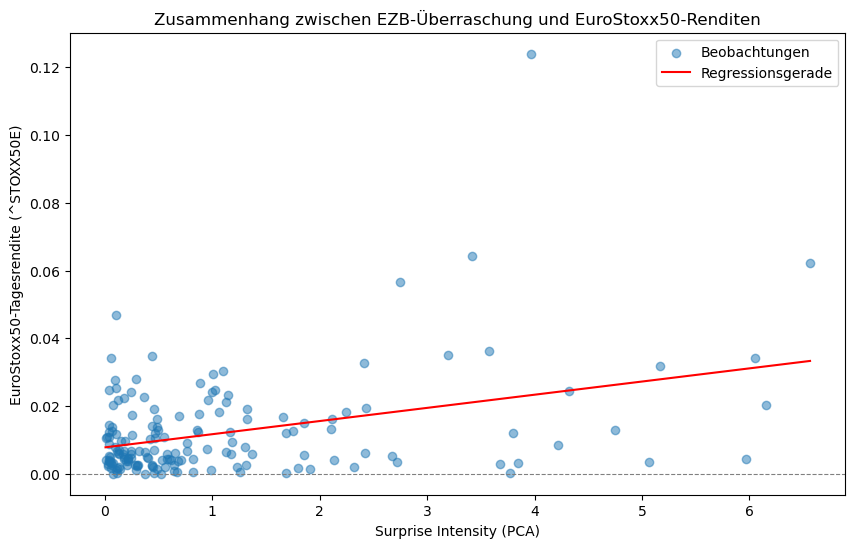

In [27]:
plt.figure(figsize=(10, 6))

# Datenpunkte
plt.scatter(merged_eurostoxx["surprise_intensity_pca"], merged_eurostoxx["EuroStoxx50_return"].abs(), alpha=0.5, label="Beobachtungen")

# Regressionsgerade
x_eurostoxx_range = np.linspace(merged_eurostoxx["surprise_intensity_pca"].min(), merged_eurostoxx["surprise_intensity_pca"].max(), 100)
y_eurostoxx_pred = model_eurostoxx.params["const"] + model_eurostoxx.params["surprise_intensity_pca"] * x_eurostoxx_range
plt.plot(x_eurostoxx_range, y_eurostoxx_pred, color="red", label="Regressionsgerade")

plt.xlabel("Surprise Intensity (PCA)")
plt.ylabel("EuroStoxx50-Tagesrendite (^STOXX50E)")
plt.title("Zusammenhang zwischen EZB-Überraschung und EuroStoxx50-Renditen")
plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)
plt.legend()
plt.show()

In [28]:
model_eurostoxx_robust = sm.OLS(merged_eurostoxx["EuroStoxx50_return"].abs(), X_eurostoxx).fit()
model_eurostoxx_robust.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     EuroStoxx50_return   R-squared:                       0.138
Model:                            OLS   Adj. R-squared:                  0.133
Method:                 Least Squares   F-statistic:                     26.04
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           9.28e-07
Time:                        13:55:15   Log-Likelihood:                 473.29
No. Observations:                 164   AIC:                            -942.6
Df Residuals:                     162   BIC:                            -936.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0.0078      0.001      5.811      0.000       0.005       0.010
surprise_intensity_pca     0.0039      0.001      5.103      0.000       0.002       0.005
==============================================================================
Omnibus:                      143.315   Durbin-Watson:                   1.609
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2526.354
Skew:                           3.072   Prob(JB):                         0.00
Kurtosis:                      21.220   Cond. No.                         2.54
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [29]:
model_eurostoxx_robust = sm.OLS(merged_eurostoxx["EuroStoxx50_return"].abs(), X_eurostoxx).fit(cov_type="HC3")
model_eurostoxx_robust.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     EuroStoxx50_return   R-squared:                       0.138
Model:                            OLS   Adj. R-squared:                  0.133
Method:                 Least Squares   F-statistic:                     7.676
Date:                Thu, 01 Oct 2026   Prob (F-statistic):            0.00625
Time:                        13:55:15   Log-Likelihood:                 473.29
No. Observations:                 164   AIC:                            -942.6
Df Residuals:                     162   BIC:                            -936.4
Df Model:                           1                                         
Covariance Type:                  HC3                                         
==========================================================================================
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0.0078      0.001      7.042      0.000       0.006       0.010
surprise_intensity_pca     0.0039      0.001      2.771      0.006       0.001       0.007
==============================================================================
Omnibus:                      143.315   Durbin-Watson:                   1.609
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2526.354
Skew:                           3.072   Prob(JB):                         0.00
Kurtosis:                      21.220   Cond. No.                         2.54
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [30]:
surprise_pca1_df = pd.DataFrame({
    "date": dates_long.values,
    "surprise_intensity_pca": np.absolute(scores_long[:, 0])
})

surprise_pca2_df = pd.DataFrame({
    "date": dates_long.values,
    "surprise_intensity_pca": np.absolute(scores_long[:, 1])
})

# 3. Merge auf das Datum
merged_pca1_bund = surprise_pca1_df.merge(returns_df, left_on="date", right_on="Date", how="inner")
merged_pca1_eurostoxx = surprise_pca1_df.merge(returns_eurostoxx_df, left_on="date", right_on="Date", how="inner")
merged_pca2_bund = surprise_pca2_df.merge(returns_df, left_on="date", right_on="Date", how="inner")
merged_pca2_eurostoxx = surprise_pca2_df.merge(returns_eurostoxx_df, left_on="date", right_on="Date", how="inner")


In [31]:
X_pca1_bund = sm.add_constant(merged_pca1_bund["surprise_intensity_pca"])
model_pca1_bund = sm.OLS(merged_pca1_bund["bund_return"].abs(), X_pca1_bund).fit()
model_pca1_bund.summary()

X_pca1_eurostoxx = sm.add_constant(merged_pca1_eurostoxx["surprise_intensity_pca"])
model_pca1_eurostoxx = sm.OLS(merged_pca1_eurostoxx["EuroStoxx50_return"].abs(), X_pca1_eurostoxx).fit()
model_pca1_eurostoxx.summary()

X_pca2_bund = sm.add_constant(merged_pca2_bund["surprise_intensity_pca"])
model_pca2_bund = sm.OLS(merged_pca2_bund["bund_return"].abs(), X_pca2_bund).fit()
model_pca2_bund.summary()

X_pca2_eurostoxx = sm.add_constant(merged_pca2_eurostoxx["surprise_intensity_pca"])
model_pca2_eurostoxx = sm.OLS(merged_pca2_eurostoxx["EuroStoxx50_return"].abs(), X_pca2_eurostoxx).fit()
model_pca2_eurostoxx.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:     EuroStoxx50_return   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.074
Method:                 Least Squares   F-statistic:                     14.10
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           0.000241
Time:                        13:55:15   Log-Likelihood:                 467.91
No. Observations:                 164   AIC:                            -931.8
Df Residuals:                     162   BIC:                            -925.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==========================================================================================
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0.0091      0.001      6.830      0.000       0.006       0.012
surprise_intensity_pca     0.0053      0.001      3.755      0.000       0.002       0.008
==============================================================================
Omnibus:                      160.020   Durbin-Watson:                   1.634
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             3535.528
Skew:                           3.537   Prob(JB):                         0.00
Kurtosis:                      24.618   Cond. No.                         1.91
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

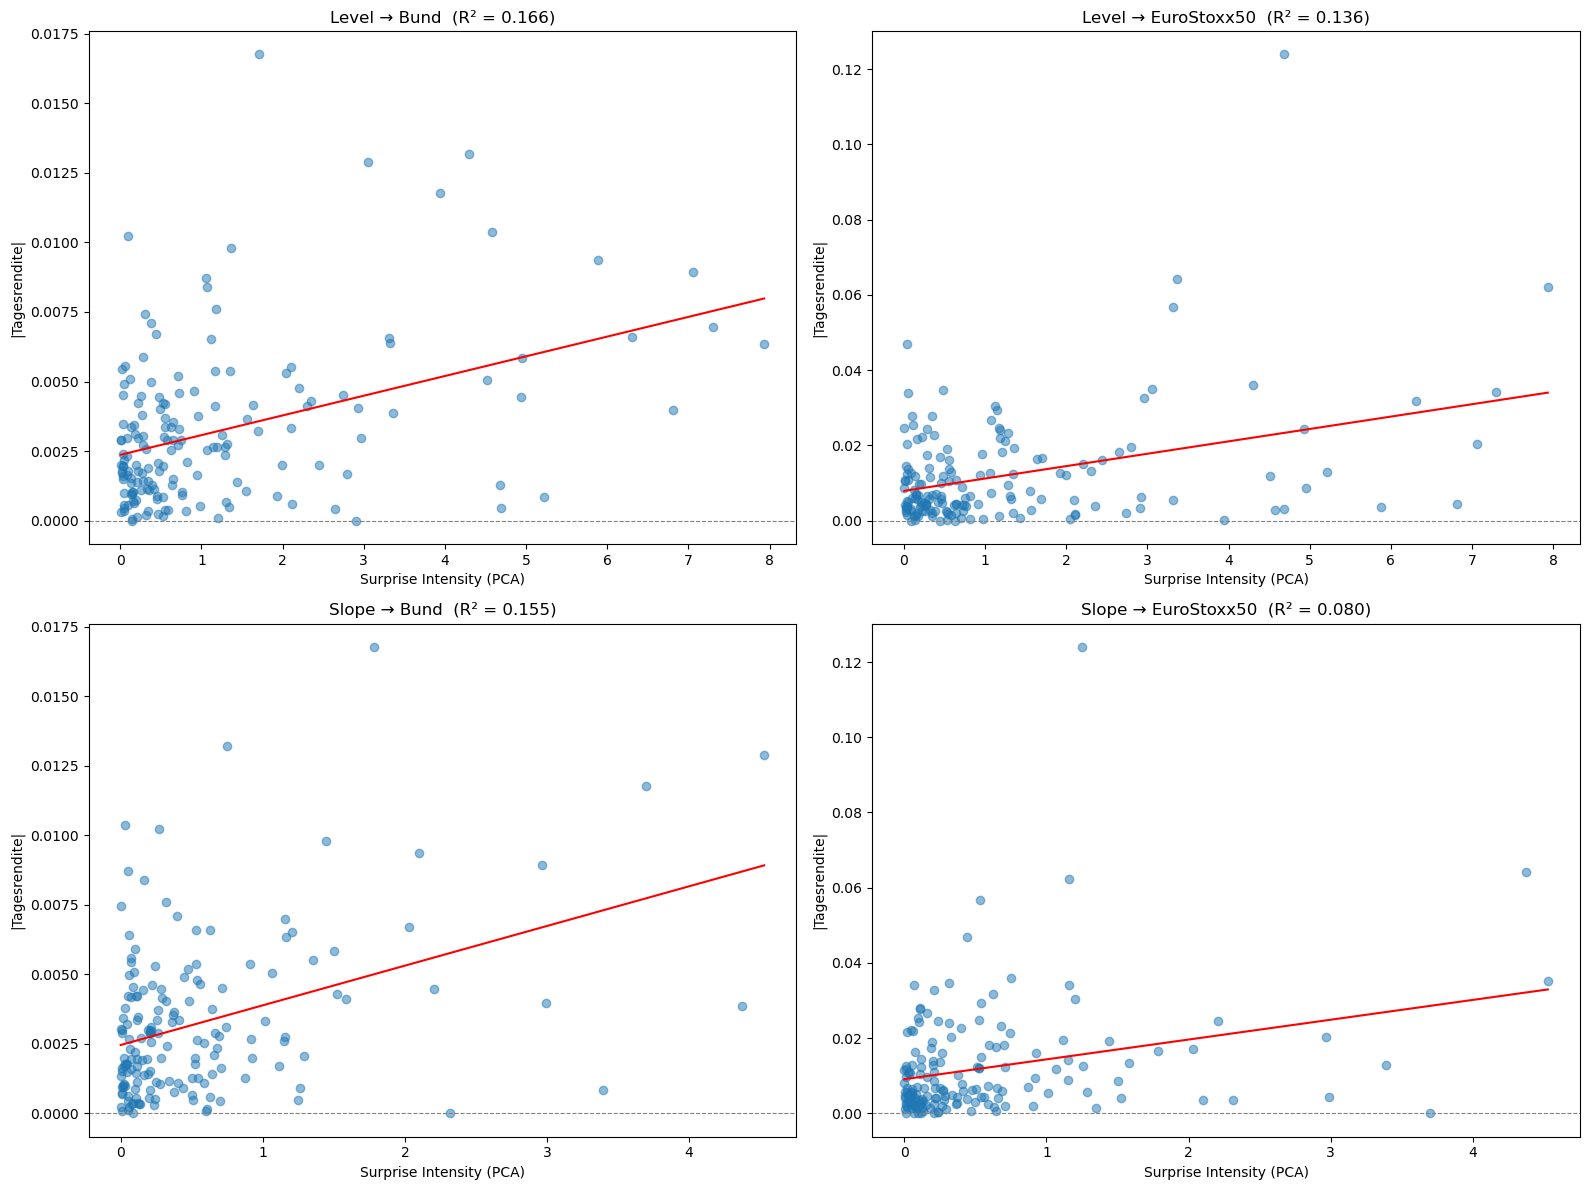

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Konfiguration: (Achse, Daten-DataFrame, x-Spalte, y-Spalte, Modell, Titel)
plots = [
    (axes[0, 0], merged_pca1_bund, "surprise_intensity_pca", "bund_return", model_pca1_bund, "Level → Bund"),
    (axes[0, 1], merged_pca1_eurostoxx, "surprise_intensity_pca", "EuroStoxx50_return", model_pca1_eurostoxx, "Level → EuroStoxx50"),
    (axes[1, 0], merged_pca2_bund, "surprise_intensity_pca", "bund_return", model_pca2_bund, "Slope → Bund"),
    (axes[1, 1], merged_pca2_eurostoxx, "surprise_intensity_pca", "EuroStoxx50_return", model_pca2_eurostoxx, "Slope → EuroStoxx50"),
]

for ax, df, x_col, y_col, model, title in plots:
    x = df[x_col]
    y = df[y_col].abs()

    ax.scatter(x, y, alpha=0.5)

    x_range = np.linspace(x.min(), x.max(), 100)
    y_pred = model.params["const"] + model.params[x_col] * x_range
    ax.plot(x_range, y_pred, color="red")

    ax.set_title(f"{title}  (R² = {model.rsquared:.3f})")
    ax.set_xlabel("Surprise Intensity (PCA)")
    ax.set_ylabel("|Tagesrendite|")
    ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.show()

/var/folders/rn/8zfs0crj6qx0sgjrmb1z2b3m0000gn/T/ipykernel_37585/1760146210.py:64: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


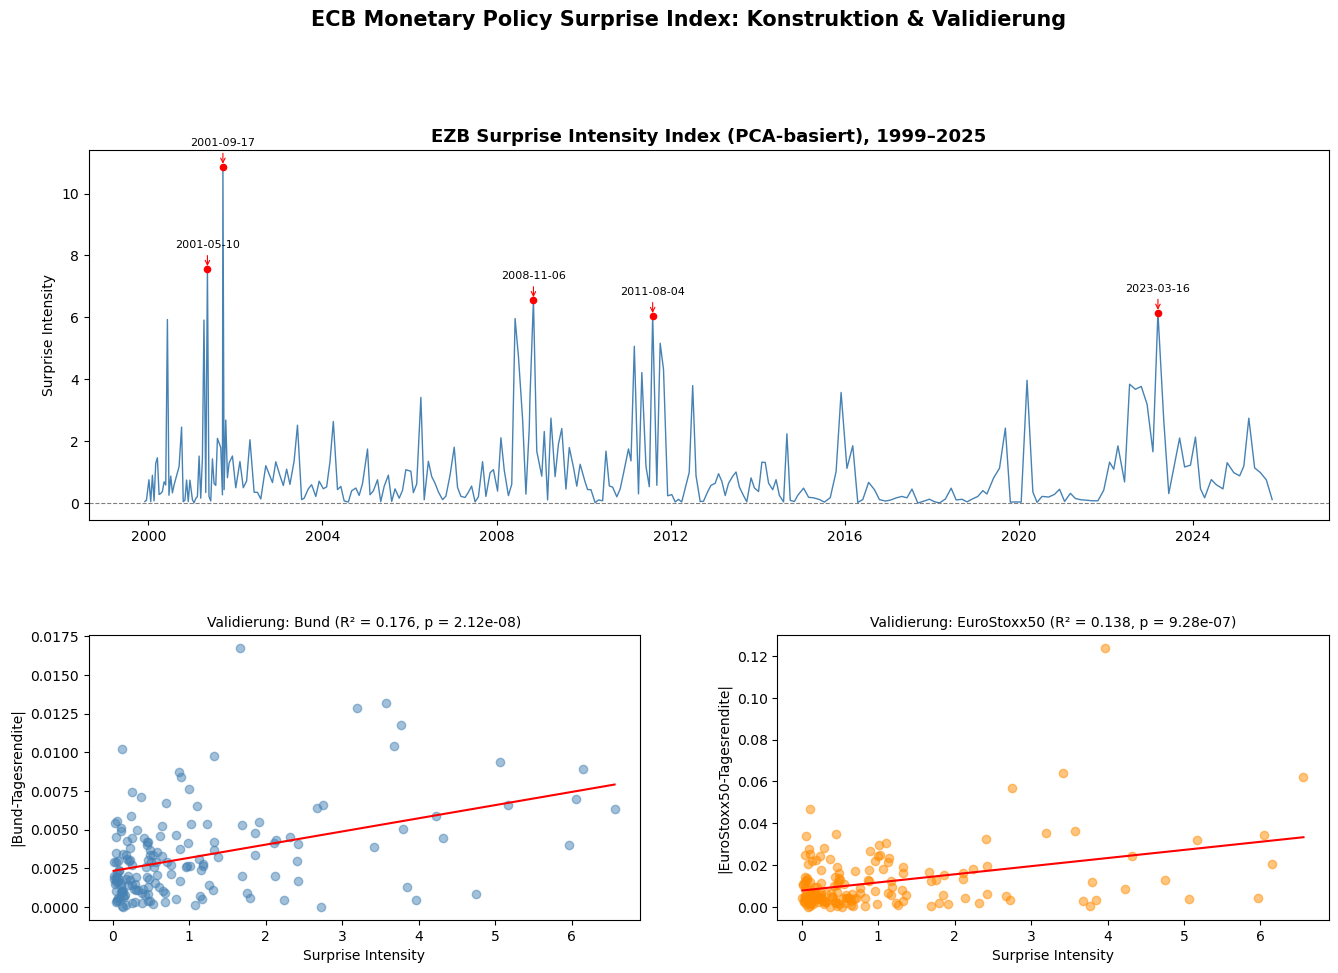

In [33]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 10))
gs = gridspec.GridSpec(2, 2, height_ratios=[1.3, 1], hspace=0.35, wspace=0.25)

# --- Oben: Zeitreihe mit beschrifteten Ausreißern ---
ax_top = fig.add_subplot(gs[0, :])
ax_top.plot(dates_long, surprise_intensity_pca, color="steelblue", linewidth=1)
ax_top.set_title("EZB Surprise Intensity Index (PCA-basiert), 1999–2025", fontsize=13, fontweight="bold")
ax_top.set_ylabel("Surprise Intensity")
ax_top.axhline(y=0, color="gray", linestyle="--", linewidth=0.8)

# Die 5 größten Ausreißer automatisch finden und beschriften
top_n = 5
top_idx = np.argsort(surprise_intensity_pca)[-top_n:]

# Hier optional eigene Ereignis-Labels statt nur des Datums eintragen
event_labels = {
    # "2008-10-08": "Koordinierte Zinssenkung",
    # "2011-08-04": "Eurokrise",
    # "2015-01-22": "QE-Ankündigung",
    # "2020-03-12": "Covid-Schock",
}

for i in top_idx:
    date = dates_long.values[i]
    value = surprise_intensity_pca[i]
    date_str = pd.Timestamp(date).strftime("%Y-%m-%d")
    label = event_labels.get(date_str, date_str)
    ax_top.annotate(
        label,
        xy=(date, value),
        xytext=(0, 15), textcoords="offset points",
        ha="center", fontsize=8,
        arrowprops=dict(arrowstyle="->", color="red", lw=0.8)
    )
    ax_top.scatter([date], [value], color="red", zorder=5, s=20)

# --- Unten links: Validierungsregression (Bund) ---
ax_bl = fig.add_subplot(gs[1, 0])
x = merged_bund["surprise_intensity_pca"]
y = merged_bund["bund_return"].abs()
ax_bl.scatter(x, y, alpha=0.5, color="steelblue")
x_range = np.linspace(x.min(), x.max(), 100)
y_pred = model_bund.params["const"] + model_bund.params["surprise_intensity_pca"] * x_range
ax_bl.plot(x_range, y_pred, color="red")
ax_bl.set_title(f"Validierung: Bund (R² = {model_bund.rsquared:.3f}, p = {model_bund.pvalues['surprise_intensity_pca']:.2e})", fontsize=10)
ax_bl.set_xlabel("Surprise Intensity")
ax_bl.set_ylabel("|Bund-Tagesrendite|")

# --- Unten rechts: Validierungsregression (EuroStoxx50) ---
ax_br = fig.add_subplot(gs[1, 1])
x2 = merged_eurostoxx["surprise_intensity_pca"]
y2 = merged_eurostoxx["EuroStoxx50_return"].abs()
ax_br.scatter(x2, y2, alpha=0.5, color="darkorange")
x2_range = np.linspace(x2.min(), x2.max(), 100)
y2_pred = model_eurostoxx.params["const"] + model_eurostoxx.params["surprise_intensity_pca"] * x2_range
ax_br.plot(x2_range, y2_pred, color="red")
ax_br.set_title(f"Validierung: EuroStoxx50 (R² = {model_eurostoxx.rsquared:.3f}, p = {model_eurostoxx.pvalues['surprise_intensity_pca']:.2e})", fontsize=10)
ax_br.set_xlabel("Surprise Intensity")
ax_br.set_ylabel("|EuroStoxx50-Tagesrendite|")

plt.suptitle("ECB Monetary Policy Surprise Index: Konstruktion & Validierung", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("surprise_index_dashboard.png", dpi=200, bbox_inches="tight")
plt.show()

In [34]:
X_pca1_bund = sm.add_constant(merged_pca1_bund["surprise_intensity_pca"])
model_pca1_bund = sm.OLS(merged_pca1_bund["bund_return"].abs(), X_pca1_bund).fit(cov_type="HC3")
print(model_pca1_bund.summary())

X_pca1_eurostoxx = sm.add_constant(merged_pca1_eurostoxx["surprise_intensity_pca"])
model_pca1_eurostoxx = sm.OLS(merged_pca1_eurostoxx["EuroStoxx50_return"].abs(), X_pca1_eurostoxx).fit(cov_type="HC3")
print(model_pca1_eurostoxx.summary())

X_pca2_bund = sm.add_constant(merged_pca2_bund["surprise_intensity_pca"])
model_pca2_bund = sm.OLS(merged_pca2_bund["bund_return"].abs(), X_pca2_bund).fit(cov_type="HC3")
print(model_pca2_bund.summary())

X_pca2_eurostoxx = sm.add_constant(merged_pca2_eurostoxx["surprise_intensity_pca"])
model_pca2_eurostoxx = sm.OLS(merged_pca2_eurostoxx["EuroStoxx50_return"].abs(), X_pca2_eurostoxx).fit(cov_type="HC3")
print(model_pca2_eurostoxx.summary())

                            OLS Regression Results                            
Dep. Variable:            bund_return   R-squared:                       0.166
Model:                            OLS   Adj. R-squared:                  0.161
Method:                 Least Squares   F-statistic:                     23.95
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           2.36e-06
Time:                        13:55:15   Log-Likelihood:                 749.39
No. Observations:                 165   AIC:                            -1495.
Df Residuals:                     163   BIC:                            -1489.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0